# SignSense — Data quality of the landmark files

Read-only check of the 5,673 files of the 15 candidate words (`validate_landmarks.py`).
Nothing is modified. The report itself is not committed (data files stay outside the repository); this notebook shows its results.

Questions: do all files open? How long are the samples? Are hands visible? Is the structure always the same?

In [1]:
from pathlib import Path

import pandas as pd

REPORT = Path(r"E:\SignSense_data\processed\validation_report.csv")
r = pd.read_csv(REPORT)

print("Files in the report:", len(r))
print("Files that could not be read:", int((~r["ok"]).sum()))
print("Samples per word:", r["sign"].nunique(), "words,", r["participant_id"].nunique(), "participants")

checks = {
    "files with frame gaps": (r["frame_gaps"] > 0).sum(),
    "files with unexpected structure": (r["bad_structure_frames"] > 0).sum(),
    "files with bad landmark_index": r["bad_index"].sum(),
    "files with duplicated landmarks": (r["duplicated_landmarks"] > 0).sum(),
    "files with partial hands": ((r["left_partial_frames"] > 0) | (r["right_partial_frames"] > 0)).sum(),
    "files with incomplete pose": (r["pose_incomplete_frames"] > 0).sum(),
    "files without any hand frame": (r["any_hand_frames"] == 0).sum(),
}
print()
for name, value in checks.items():
    print(f"{name}: {int(value)}")

Files in the report: 5673
Files that could not be read: 0
Samples per word: 15 words, 21 participants

files with frame gaps: 2
files with unexpected structure: 0
files with bad landmark_index: 0
files with duplicated landmarks: 0
files with partial hands: 0
files with incomplete pose: 0
files without any hand frame: 0


In [2]:
gaps = r[r["frame_gaps"] > 0]
print(gaps[["sequence_id", "participant_id", "sign", "n_frames", "frame_min", "frame_max", "frame_gaps"]].to_string(index=False))

ROOT = Path(r"E:\SignSense_data\raw\landmarks")
for row in gaps.itertuples():
    frames = pd.read_parquet(ROOT / row.path, columns=["frame"])["frame"].unique()
    present = set(frames.tolist())
    missing = [f for f in range(row.frame_min, row.frame_max + 1) if f not in present]
    print(row.sequence_id, "missing frames:", missing)

 sequence_id  participant_id sign  n_frames  frame_min  frame_max  frame_gaps
  1125180648           30680 home       119         76        206          12
   940100783           61333  yes       247         76        325           3
1125180648 missing frames: [107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118]
940100783 missing frames: [167, 200, 216]


count    5673.000000
mean       37.875022
std        43.853022
min         2.000000
25%        11.000000
50%        22.000000
75%        44.000000
max       308.000000
Name: n_frames, dtype: float64
samples with fewer than 5 frames: 22 (0.4%)
samples with fewer than 10 frames: 1162 (20.5%)
samples with fewer than 15 frames: 1814 (32.0%)
samples with fewer than 30 frames: 3550 (62.6%)
samples with more than 100 frames: 504 (8.9%)


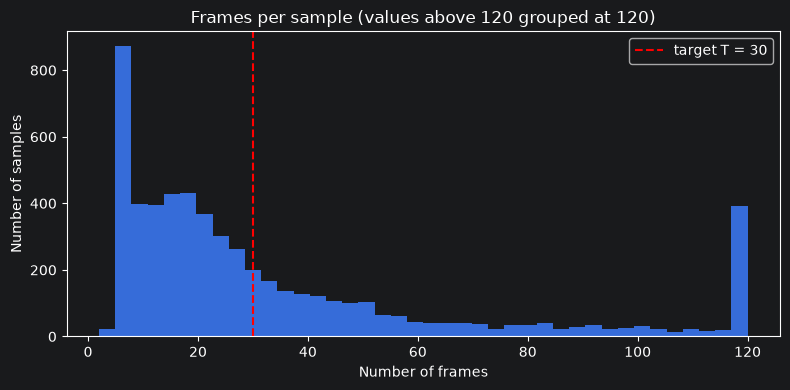

In [3]:
import matplotlib.pyplot as plt

n = r["n_frames"]
print(n.describe())
for limit in (5, 10, 15, 30):
    print(f"samples with fewer than {limit} frames: {int((n < limit).sum())} ({(n < limit).mean():.1%})")
print("samples with more than 100 frames:", int((n > 100).sum()), f"({(n > 100).mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(n.clip(upper=120), bins=40)
ax.axvline(30, color="red", linestyle="--", label="target T = 30")
ax.set_title("Frames per sample (values above 120 grouped at 120)")
ax.set_xlabel("Number of frames")
ax.set_ylabel("Number of samples")
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
r["any_hand_ratio"] = r["any_hand_frames"] / r["n_frames"]
r["lt10"] = r["n_frames"] < 10
r["lt30"] = r["n_frames"] < 30


def summary(by):
    return (
        r.groupby(by)
        .agg(
            samples=("n_frames", "size"),
            median_frames=("n_frames", "median"),
            share_lt10=("lt10", "mean"),
            share_lt30=("lt30", "mean"),
            hand_ratio=("any_hand_ratio", "mean"),
        )
        .round(2)
    )


print(summary("participant_id").sort_values("median_frames").to_string())
print()
print(summary("sign").sort_values("median_frames").to_string())

                samples  median_frames  share_lt10  share_lt30  hand_ratio
participant_id                                                            
37779               283            8.0        0.64        1.00        0.72
18796               195           10.0        0.48        0.75        0.61
30680               235           11.0        0.43        0.86        0.57
25571               233           11.0        0.41        0.84        0.67
2044                287           14.0        0.29        0.95        0.68
53618               284           17.0        0.24        0.67        0.64
37055               267           19.0        0.19        0.75        0.60
62590               277           19.0        0.12        0.84        0.86
36257               284           19.5        0.19        0.58        0.62
4718                216           20.0        0.25        0.63        0.56
55372               282           22.0        0.11        0.71        0.69
16069               296  

## Verified Findings

**Data quality validation — 5,673 files across 15 candidate words and 21 participants**

- All 5,673 files were readable.
- All frames had the expected structure: 468 face, 21 left-hand, 33 pose, and 21 right-hand landmarks.
- Landmark indices were consistent, with no duplicated landmarks.
- No files lacked detected hands, and no partial hands were found.
- Two files had missing frame numbers:
  - `home`, participant `30680`, sequence `1125180648`: frames 107–118.
  - `yes`, participant `61333`, sequence `940100783`: frames 167, 200, and 216.

**Sequence length analysis**

- Frames per sample: minimum 2, median 22, maximum 308.
- 3,550 samples (62.6%) had fewer than 30 frames.
- 1,162 samples (20.5%) had fewer than 10 frames.
- 22 samples had fewer than 5 frames.
- 504 samples (8.9%) had more than 100 frames.
- Median sequence length varied from 8 to 47 frames across participants, and from 15 to 30 frames across words.

**Additional verification**

- In 116,671,695 rows, `x`, `y`, and `z` were always missing together.
- An independent check of 200 random files confirmed the reported frame counts and frames containing hands.
- The `path` column matched participant and sequence IDs in every report row.
- The validation function correctly detected six intentionally introduced defects: partial hand, missing pose value, missing pose row, duplicated row, missing frame, and invalid landmark index.